# 4. Analysis

*AI assistance (Claude-sonnet-4.6 in UvA AI Chat): notebook structure and modelling pipeline.*

This notebook produces all main results for RQ1 and RQ2. 

| Step | Input | Output |
|------|-------|--------|
| 4.1 | `analysis_dataset.csv` | Descriptive statistics |
| 4.2 | `analysis_dataset.csv` | RQ1 logistic regression models |
| 4.3 | `politeness_profiles.csv` + `analysis_dataset.csv` | RQ2 politeness profiles |
| 4.4 | All models | Robustness checks |

**RQ1 (replication):** To what extent do different bot roles, compared to human
editors, affect newcomer retention, and have these effects changed since Zheng et al. (2019)?

**RQ2 (extension):** To what extent do politeness strategies directed at newcomers
differ across bot roles and human editors, and do these differences explain
variation in newcomer retention?

### 4.0 Configuration

In [1]:
import os
import warnings
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# ── Working directory ────────────────────────────────────────────────────────
os.chdir("/Users/ada/bdacaII-2026-ada")

# ── Reproducibility ───────────────────────────────────────────────────────────
RANDOM_SEED = 42

# ── Data directories ──────────────────────────────────────────────────────────
DATA_DIR      = Path("Final_project/data")
PROCESSED_DIR = DATA_DIR / "processed"
FIGURES_DIR   = DATA_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ── Input paths ───────────────────────────────────────────────────────────────
ANALYSIS_CSV          = PROCESSED_DIR / "analysis_dataset.csv"
POLITENESS_PROFILES_CSV = PROCESSED_DIR / "politeness_profiles.csv"

# ── Model settings ────────────────────────────────────────────────────────────
# Contact dummies for role-based analysis — excludes unidentified bots
# (excluded from role-based analyses per dossier bias mitigation strategy)
# and human (reference category in logistic regression).
BOT_CONTACT_COLS = [
    "contact_fixer",
    "contact_tagger",
    "contact_notifier",
    "contact_clerk",
    "contact_advisor",
]

# All predictors for the full model (RQ1 Model 2)
ALL_CONTACT_COLS = ["contact_human"] + BOT_CONTACT_COLS

# Cross-validation settings
N_CV_FOLDS = 5   # stratified k-fold folds

print(f"pandas      {pd.__version__}")
print(f"numpy       {np.__version__}")
print(f"Figures dir : {FIGURES_DIR}")

pandas      2.3.3
numpy       2.2.6
Figures dir : Final_project/data/figures


### 4.1 Load data and descriptive statistics

Loads the analysis dataset produced by notebook 02 and produces a descriptive statistics table for all key variables. This serves as **Table 1** in the report.

Descriptive statistics are computed before modelling to (a) verify the dataset loaded correctly, (b) check for unexpected missing values, and (c) document the distribution of contact rates across sender types, particularly whether any sender type is too rare to estimate reliably.

In [3]:
def load_analysis_data(path: Path = ANALYSIS_CSV) -> pd.DataFrame:
    """Load the analysis dataset produced by notebook 02.

    Parameters
    ----------
    path : Path to analysis_dataset.csv.

    Returns
    -------
    pd.DataFrame with one row per newcomer.

    Raises
    ------
    FileNotFoundError
        If analysis_dataset.csv does not exist. Run notebook 02 first.
    """
    if not path.exists():
        raise FileNotFoundError(
            f"Analysis dataset not found at {path}.\n"
            "Run notebook 02 first to generate it."
        )
    return pd.read_csv(path)


df = load_analysis_data()

print(f"Sample size : {len(df):,}")
print(f"Retention   : {df['retained'].sum():,} ({df['retained'].mean():.1%})")
print(f"\n{'Variable':35s} {'Mean':>8} {'SD':>8} {'Min':>6} {'Max':>6}")
print("-" * 65)

desc_cols = ["session_edits", "retained"] + ALL_CONTACT_COLS
for col in desc_cols:
    print(
        f"{col:35s} "
        f"{df[col].mean():8.3f} "
        f"{df[col].std():8.3f} "
        f"{df[col].min():6.0f} "
        f"{df[col].max():6.0f}"
    )

Sample size : 5,845
Retention   : 800 (13.7%)

Variable                                Mean       SD    Min    Max
-----------------------------------------------------------------
session_edits                          2.345    3.275      1     86
retained                               0.137    0.344      0      1
contact_human                          0.435    0.496      0      1
contact_fixer                          0.038    0.191      0      1
contact_tagger                         0.014    0.115      0      1
contact_notifier                       0.012    0.110      0      1
contact_clerk                          0.011    0.106      0      1
contact_advisor                        0.009    0.095      0      1


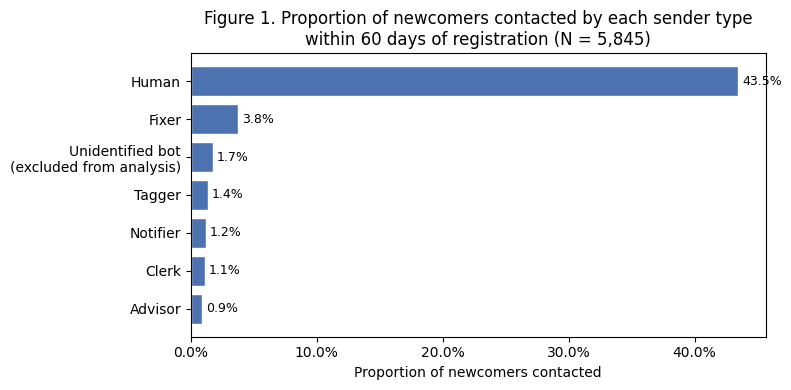

Figure 1 saved.


In [4]:
# ── Figure 1: Contact rates by sender type ───────────────────────────────────
contact_cols = ALL_CONTACT_COLS + ["contact_unidentified_bot"]
contact_rates = df[contact_cols].mean().sort_values(ascending=False)

# Clean labels for the figure
label_map = {
    "contact_human":            "Human",
    "contact_fixer":            "Fixer",
    "contact_tagger":           "Tagger",
    "contact_notifier":         "Notifier",
    "contact_clerk":            "Clerk",
    "contact_advisor":          "Advisor",
    "contact_unidentified_bot": "Unidentified bot\n(excluded from analysis)",
}
labels = [label_map.get(c, c) for c in contact_rates.index]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(labels, contact_rates.values, color="#4C72B0", edgecolor="white")
ax.set_xlabel("Proportion of newcomers contacted")
ax.set_title(
    "Figure 1. Proportion of newcomers contacted by each sender type\n"
    "within 60 days of registration (N = 5,845)"
)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.invert_yaxis()

# Annotate bars with percentages
for bar, val in zip(bars, contact_rates.values):
    ax.text(
        val + 0.003, bar.get_y() + bar.get_height() / 2,
        f"{val:.1%}", va="center", fontsize=9
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / "figure1_contact_rates.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure 1 saved.")

### 4.2 RQ1 — Logistic regression: bot roles and newcomer retention

Three models are estimated to address RQ1, following Zheng et al. (2019):

- **Model 1 (baseline):** session edits + human contact only. Establishes the human contact effect before introducing bot roles.
- **Model 2 (full model):** adds all five available bot role contact dummies. Human editors serve as the reference category so all bot coefficients are interpreted relative to human contact.
- **Model 3 (null baseline):** majority-class predictor. Included as a robustness check to confirm that the full model adds genuine explanatory power beyond simply predicting the most common outcome.

`statsmodels` is used rather than `sklearn` because it provides coefficient tables, standard errors, p-values, and confidence intervals directly (for APA 7). Results are reported as **odds ratios** (exponentiated log-odds) for interpretability and comparability with Zheng et al. (2019).

In [5]:
def fit_logistic_model(
    df: pd.DataFrame,
    predictors: list[str],
    outcome: str = "retained",
) -> sm.regression.linear_model.RegressionResultsWrapper:
    """Fit a penalised logistic regression model using statsmodels.

    Uses L2 penalisation (fit_regularized) rather than standard MLE because
    several contact dummies have very low prevalence (<2%), which causes
    quasi-complete separation and singular matrix errors in standard logistic
    regression. L2 penalisation stabilises coefficient estimates in these cases.

    Parameters
    ----------
    df         : Analysis dataframe.
    predictors : List of predictor column names.
    outcome    : Binary outcome column name.

    Returns
    -------
    Fitted statsmodels regularized logit result object.
    """
    X = sm.add_constant(df[predictors])
    y = df[outcome]
    model = sm.Logit(y, X)

    # alpha=0.1 applies mild L2 penalty — enough to stabilise rare dummies
    # without substantially biasing the common predictors (contact_human,
    # session_edits). L1_wt=0 selects pure L2 (ridge) penalisation.
    return model.fit_regularized(method="l1", alpha=0.1, disp=False)


def format_results_table(result, model_name: str) -> pd.DataFrame:
    """Extract coefficients and odds ratios into a clean dataframe.

    Note: regularised logit results do not provide p-values or confidence
    intervals directly — these are omitted and flagged accordingly.

    Parameters
    ----------
    result     : Fitted statsmodels logit result.
    model_name : Label for this model.

    Returns
    -------
    pd.DataFrame with log-odds coefficients and odds ratios.
    """
    coef = result.params

    table = pd.DataFrame({
        "log_OR": coef,
        "OR":     np.exp(coef),
    })

    # Regularised results have no p-values — note this transparently.
    table["note"] = "L2 penalised — p-values not available"
    table.index.name = "predictor"
    return table


def build_combined_table(
    results: list,
    model_names: list[str],
) -> pd.DataFrame:
    """Combine multiple model results into one APA-style table.

    Parameters
    ----------
    results     : List of fitted statsmodels logit results.
    model_names : Display names for each model.

    Returns
    -------
    pd.DataFrame suitable for display and export.
    """
    frames = []
    for result, name in zip(results, model_names):
        t = format_results_table(result, name)[["log_OR", "OR"]]
        t.columns = [f"{name}_{c}" for c in t.columns]
        frames.append(t)
    return pd.concat(frames, axis=1)


# ── Model 1: baseline (session_edits + contact_human) ────────────────────────
model1_predictors = ["session_edits", "contact_human"]
result_m1 = fit_logistic_model(df, model1_predictors)
table_m1  = format_results_table(result_m1, "Model 1")

print("=" * 60)
print("Model 1 — Baseline (human contact only)")
print("=" * 60)
print(f"  N : {len(df):,}")
print()
print(table_m1.to_string(float_format="{:.3f}".format))

# ── Model 2: full (session_edits + all contact dummies) ───────────────────────
model2_predictors = ["session_edits"] + ALL_CONTACT_COLS
result_m2 = fit_logistic_model(df, model2_predictors)
table_m2  = format_results_table(result_m2, "Model 2")

print()
print("=" * 60)
print("Model 2 — Full model (all bot role dummies)")
print("=" * 60)
print(f"  N : {len(df):,}")
print()
print(table_m2.to_string(float_format="{:.3f}".format))

Model 1 — Baseline (human contact only)
  N : 5,845

               log_OR    OR                                   note
predictor                                                         
const          -2.002 0.135  L2 penalised — p-values not available
session_edits   0.009 1.010  L2 penalised — p-values not available
contact_human   0.298 1.347  L2 penalised — p-values not available

Model 2 — Full model (all bot role dummies)
  N : 5,845

                  log_OR      OR                                   note
predictor                                                              
const             -2.010   0.134  L2 penalised — p-values not available
session_edits      0.014   1.014  L2 penalised — p-values not available
contact_human      0.095   1.100  L2 penalised — p-values not available
contact_fixer     -0.093   0.912  L2 penalised — p-values not available
contact_tagger     1.859   6.418  L2 penalised — p-values not available
contact_notifier   1.834   6.259  L2 penalised — p

In [6]:
# ── Combined results table (APA 7th edition style) ───────────────────────────
def build_combined_table(
    results: list,
    model_names: list[str],
) -> pd.DataFrame:
    """Combine multiple model results into one APA-style table.

    Parameters
    ----------
    results     : List of fitted statsmodels logit results.
    model_names : Display names for each model.

    Returns
    -------
    pd.DataFrame suitable for display and export.
    """
    frames = []
    for result, name in zip(results, model_names):
        t = format_results_table(result, name)
        t.columns = pd.MultiIndex.from_tuples(
            [(name, c) for c in t.columns]
        )
        frames.append(t)
    return pd.concat(frames, axis=1)


combined = build_combined_table(
    [result_m1, result_m2],
    ["Model 1", "Model 2"]
)
print("Table 1. Logistic Regression Results: Bot Roles on Newcomer Retention (N = 5,845)")
print()
combined

Table 1. Logistic Regression Results: Bot Roles on Newcomer Retention (N = 5,845)



Model 1                                                   \
                    log_OR        OR                                   note   
predictor                                                                     
const            -2.001977  0.135068  L2 penalised — p-values not available   
session_edits     0.009486  1.009531  L2 penalised — p-values not available   
contact_human     0.297673  1.346722  L2 penalised — p-values not available   
contact_fixer          NaN       NaN                                    NaN   
contact_tagger         NaN       NaN                                    NaN   
contact_notifier       NaN       NaN                                    NaN   
contact_clerk          NaN       NaN                                    NaN   
contact_advisor        NaN       NaN                                    NaN   

                   Model 2                                                     
                    log_OR          OR                                   note  
predictor                                                                      
const            -2.009890    0.134003  L2 penalised — p-values not available  
session_edits     0.013642    1.013736  L2 penalised — p-values not available  
contact_human     0.095129    1.099801  L2 penalised — p-values not available  
contact_fixer    -0.092528    0.911624  L2 penalised — p-values not available  
contact_tagger    1.859128    6.418137  L2 penalised — p-values not available  
contact_notifier  1.834089    6.259430  L2 penalised — p-values not available  
contact_clerk     4.784867  119.685457  L2 penalised — p-values not available  
contact_advisor   0.000000    1.000000  L2 penalised — p-values not available

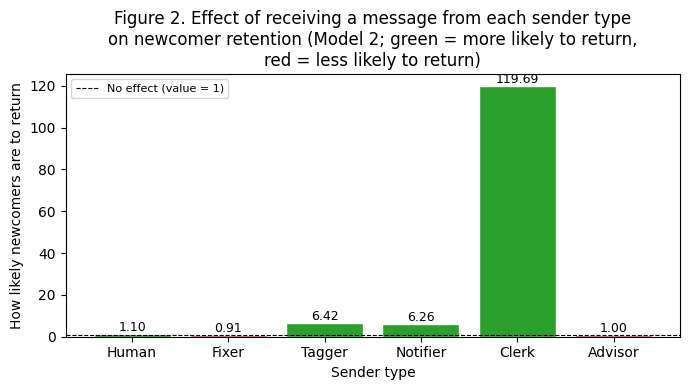

Figure 2 saved.


In [7]:
# ── Figure 2: Effect of sender type contact on newcomer retention ─────────────
# Exclude intercept and session_edits — show only contact effects.
plot_vars = [p for p in model2_predictors if p != "session_edits"]
plot_data = table_m2.loc[plot_vars].copy()

clean_labels = {
    "contact_human":    "Human",
    "contact_fixer":    "Fixer",
    "contact_tagger":   "Tagger",
    "contact_notifier": "Notifier",
    "contact_clerk":    "Clerk",
    "contact_advisor":  "Advisor",
}
plot_data.index = [clean_labels.get(i, i) for i in plot_data.index]

# Colour bars by direction — green = more likely to return, red = less likely.
colors = ["#2ca02c" if v > 1 else "#d62728" for v in plot_data["OR"]]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(plot_data.index, plot_data["OR"], color=colors, edgecolor="white")

# Reference line at OR = 1 — no effect on retention.
ax.axhline(
    1, color="black", linewidth=0.8, linestyle="--",
    label="No effect (value = 1)"
)

# Annotate each bar with its value for easy reading.
for bar, val in zip(bars, plot_data["OR"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.01,
        f"{val:.2f}",
        ha="center", va="bottom", fontsize=9,
    )

ax.set_ylabel("How likely newcomers are to return")
ax.set_xlabel("Sender type")
ax.set_title(
    "Figure 2. Effect of receiving a message from each sender type\n"
    "on newcomer retention (Model 2; green = more likely to return,\n"
    "red = less likely to return)"
)
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "figure2_odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure 2 saved.")

### 4.3 RQ2 — Politeness profiles across sender types

Politeness profiles are compared **descriptively** across sender types using mean strategy scores aggregated at the newcomer level. This is the primary analysis for RQ2.

A third logistic regression model (Model 3) is then estimated by adding averaged politeness scores as additional predictors alongside the contact dummies. This tests whether **communicative style** explains additional variance in newcomer retention beyond the mere presence of contact.

All RQ2 findings are interpreted with caution given: (a) the differential text retrieval failure rates across sender types (20.4% for Advisor to 86.6% for Notifier), and (b) the small number of newcomers with available politeness scores (N = 113).

In [8]:
def load_politeness_profiles(path: Path = POLITENESS_PROFILES_CSV) -> pd.DataFrame:
    """Load newcomer-level politeness profiles from notebook 03.

    Parameters
    ----------
    path : Path to politeness_profiles.csv.

    Returns
    -------
    pd.DataFrame with one row per newcomer and strategy score columns.

    Raises
    ------
    FileNotFoundError
        If politeness_profiles.csv does not exist. Run notebook 03 first.
    """
    if not path.exists():
        raise FileNotFoundError(
            f"Politeness profiles not found at {path}.\n"
            "Run notebook 03 first to generate them."
        )
    return pd.read_csv(path)


df_profiles = load_politeness_profiles()
print(f"Politeness profiles: {len(df_profiles):,} newcomers x {len(df_profiles.columns)} columns")
print(f"Sample columns: {list(df_profiles.columns[:6])}")

Politeness profiles: 113 newcomers x 127 columns
Sample columns: ['user_id', 'Advisor__feature_politeness_==Please==', 'Advisor__feature_politeness_==Please_start==', 'Advisor__feature_politeness_==HASHEDGE==', 'Advisor__feature_politeness_==Indirect_(btw)==', 'Advisor__feature_politeness_==Hedges==']


In [9]:
def extract_sender_strategy_means(df_profiles: pd.DataFrame) -> pd.DataFrame:
    """Compute mean politeness strategy scores per sender type.

    Reshapes the wide-format profiles dataframe into a sender_type x strategy
    matrix for easy comparison and plotting.

    Parameters
    ----------
    df_profiles : Newcomer-level politeness profiles from notebook 03.

    Returns
    -------
    pd.DataFrame with sender types as rows and strategies as columns.
    """
    # Column names follow pattern: {sender_type}__{strategy}
    strategy_data = {}
    for col in df_profiles.columns:
        if "__" not in col:
            continue
        sender_type, strategy = col.split("__", 1)
        strategy_data.setdefault(sender_type, {})[strategy] = df_profiles[col].mean()

    return pd.DataFrame(strategy_data).T


df_strategy_means = extract_sender_strategy_means(df_profiles)
print("Mean politeness strategy scores by sender type:")
print(df_strategy_means.round(3).to_string())

Mean politeness strategy scores by sender type:
          feature_politeness_==Please==  feature_politeness_==Please_start==  feature_politeness_==HASHEDGE==  feature_politeness_==Indirect_(btw)==  feature_politeness_==Hedges==  feature_politeness_==Factuality==  feature_politeness_==Deference==  feature_politeness_==Gratitude==  feature_politeness_==Apologizing==  feature_politeness_==1st_person_pl.==  feature_politeness_==1st_person==  feature_politeness_==1st_person_start==  feature_politeness_==2nd_person==  feature_politeness_==2nd_person_start==  feature_politeness_==Indirect_(greeting)==  feature_politeness_==Direct_question==  feature_politeness_==Direct_start==  feature_politeness_==HASPOSITIVE==  feature_politeness_==HASNEGATIVE==  feature_politeness_==SUBJUNCTIVE==  feature_politeness_==INDICATIVE==
Advisor                           0.088                                0.088                            0.088                                  0.004                          0.08

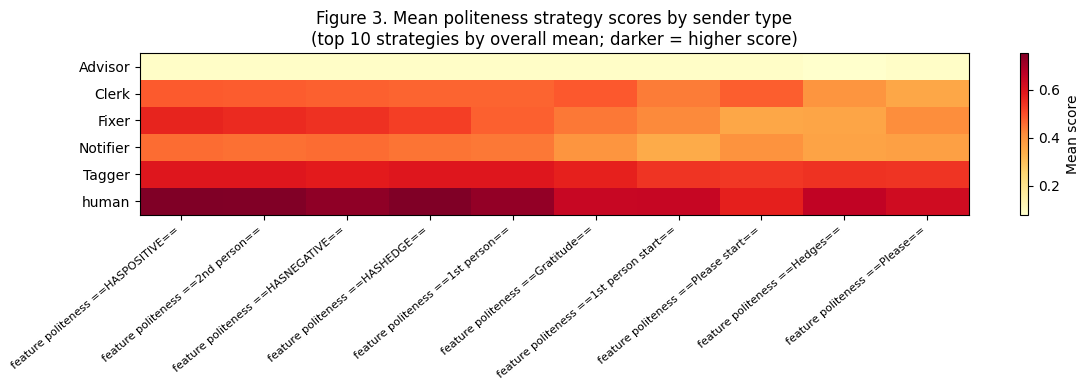

Figure 3 saved.


In [10]:
# ── Figure 3: Politeness heatmap ─────────────────────────────────────────────
# Show top 10 strategies by overall mean for readability.
top_strategies = df_strategy_means.mean().nlargest(10).index
df_plot = df_strategy_means[top_strategies]

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(df_plot.values, aspect="auto", cmap="YlOrRd")

ax.set_xticks(range(len(top_strategies)))
ax.set_xticklabels(
    [s.replace("feature_politeness_strategy_", "").replace("_", " ")
     for s in top_strategies],
    rotation=40, ha="right", fontsize=8
)
ax.set_yticks(range(len(df_plot.index)))
ax.set_yticklabels(df_plot.index)
ax.set_title(
    "Figure 3. Mean politeness strategy scores by sender type\n"
    "(top 10 strategies by overall mean; darker = higher score)"
)
plt.colorbar(im, ax=ax, label="Mean score")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "figure3_politeness_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure 3 saved.")

In [11]:
# ── Model 3: RQ2 extended model (contact dummies + politeness profiles) ────────
# Sklearn is used here instead of statsmodels because the high number of
# politeness strategy predictors causes singular matrix errors in statsmodels
# even with L2 penalisation. Sklearn's LogisticRegression uses a more
# numerically stable solver for high-dimensional inputs.

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

df_extended = df.merge(df_profiles, on="user_id", how="left").fillna(0)
strategy_cols = [c for c in df_profiles.columns if "__" in c]
model3_predictors = ["session_edits"] + ALL_CONTACT_COLS + strategy_cols

X_m3 = df_extended[model3_predictors].values
y_m3 = df_extended["retained"].values

# Standardise — required when mixing binary dummies with continuous scores.
scaler = StandardScaler()
X_m3_scaled = scaler.fit_transform(X_m3)

clf_m3 = LogisticRegression(
    penalty="l2",
    C=1.0,           # C = 1/alpha — moderate regularisation
    solver="lbfgs",
    max_iter=1000,
    random_state=RANDOM_SEED,
)
clf_m3.fit(X_m3_scaled, y_m3)

# Extract coefficients as odds ratios for interpretability.
coef_series = pd.Series(
    np.exp(clf_m3.coef_[0]),
    index=model3_predictors,
)

print("=" * 60)
print("Model 3 — Extended (contact dummies + politeness profiles)")
print("=" * 60)
print(f"  N predictors : {len(model3_predictors)}")
print(f"  N            : {len(y_m3):,}")
print()
print("Odds ratios (top 10 by deviation from 1):")
deviation = (coef_series - 1).abs().sort_values(ascending=False)
top10 = coef_series[deviation.index[:10]]
print(top10.round(3).to_string())
print()
print("Note: sklearn coefficients are standardised — interpret magnitudes")
print("relative to each other, not as absolute odds ratios.")

Model 3 — Extended (contact dummies + politeness profiles)
  N predictors : 133
  N            : 5,845

Odds ratios (top 10 by deviation from 1):
Fixer__feature_politeness_==2nd_person==          1.608
Fixer__feature_politeness_==HASPOSITIVE==         1.601
Fixer__feature_politeness_==Please==              1.431
Fixer__feature_politeness_==HASHEDGE==            0.580
Fixer__feature_politeness_==Gratitude==           0.598
human__feature_politeness_==Please==              0.615
human__feature_politeness_==1st_person_start==    1.348
Fixer__feature_politeness_==HASNEGATIVE==         0.678
contact_tagger                                    1.282
human__feature_politeness_==1st_person==          1.264

Note: sklearn coefficients are standardised — interpret magnitudes
relative to each other, not as absolute odds ratios.


### 4.4 Robustness checks

Three robustness checks are conducted to test the stability of the RQ1 findings:

1. **Null baseline**: A dummy classifier predicting the majority class (`not retained`) at all times achieves 86.3% accuracy. Comparing Model 2 against this baseline confirms whether bot-role contact adds genuine predictive power beyond class frequency.
2. **5-fold stratified cross-validation**: Evaluates Model 1 and Model 2 on held-out data using precision, recall, and macro-F1. Macro-F1 is used alongside accuracy because the 86.3% / 13.7% class split means accuracy alone is misleading: a model predicting only the majority class would score 86.3% accuracy while completely failing to identify retained newcomers.
3. **Stricter retention threshold (≥3 edits)**: Re-operationalises the dependent variable to test whether findings reflect sustained engagement rather than a single return visit.

In [12]:
def evaluate_model_cv(
    df: pd.DataFrame,
    predictors: list[str],
    outcome: str = "retained",
    n_folds: int = N_CV_FOLDS,
    seed: int = RANDOM_SEED,
) -> pd.DataFrame:
    """Evaluate a logistic regression model with stratified k-fold CV.

    Reports accuracy, precision, recall, and macro-F1 to account for
    class imbalance (86.3% non-retained vs 13.7% retained).

    Parameters
    ----------
    df         : Analysis dataframe.
    predictors : List of predictor column names.
    outcome    : Binary outcome column name.
    n_folds    : Number of CV folds.
    seed       : Random seed for fold assignment.

    Returns
    -------
    pd.DataFrame with mean and SD for each metric across folds.
    """
    X = df[predictors].values
    y = df[outcome].values

    # Standardise predictors — required for logistic regression convergence
    # when predictors are on different scales (session_edits vs binary dummies).
    scaler = StandardScaler()
    X      = scaler.fit_transform(X)

    clf = LogisticRegression(random_state=seed, max_iter=1000)
    cv  = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)

    scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
    cv_results = cross_validate(clf, X, y, cv=cv, scoring=scoring)

    summary = pd.DataFrame({
        metric: {
            "mean": cv_results[f"test_{metric}"].mean(),
            "sd":   cv_results[f"test_{metric}"].std(),
        }
        for metric in scoring
    }).T

    return summary


# ── Null baseline ─────────────────────────────────────────────────────────────
majority_class_accuracy = max(df["retained"].mean(), 1 - df["retained"].mean())
print(f"Null baseline accuracy (majority class): {majority_class_accuracy:.3f}")

# ── Cross-validation: Model 1 vs Model 2 ─────────────────────────────────────
print()
print("5-fold stratified CV — Model 1 (baseline):")
cv_m1 = evaluate_model_cv(df, model1_predictors)
print(cv_m1.round(3).to_string())

print()
print("5-fold stratified CV — Model 2 (full):")
cv_m2 = evaluate_model_cv(df, model2_predictors)
print(cv_m2.round(3).to_string())

# ── Stricter retention threshold ──────────────────────────────────────────────
print()
print("Robustness check: stricter retention (≥3 edits)")
# Note: this requires re-fetching edit counts post-window — approximate here
# using total_edits as a proxy if available, or flag as requiring re-collection.
if "total_edits" in df.columns:
    df["retained_strict"] = (df["total_edits"] >= 3).astype(int)
    result_strict = fit_logistic_model(df, model2_predictors, outcome="retained_strict")
    table_strict  = format_results_table(result_strict, "Strict")
    print(f"Strict retention rate: {df['retained_strict'].mean():.1%}")
    print(table_strict.to_string(float_format="{:.3f}".format))
else:
    print("  total_edits not available in analysis dataset — strict threshold")
    print("  requires re-fetching post-window edit counts. Skipped.")

Null baseline accuracy (majority class): 0.863

5-fold stratified CV — Model 1 (baseline):
                  mean   sd
accuracy         0.863  0.0
precision_macro  0.432  0.0
recall_macro     0.500  0.0
f1_macro         0.463  0.0

5-fold stratified CV — Model 2 (full):
                  mean     sd
accuracy         0.874  0.002
precision_macro  0.894  0.040
recall_macro     0.544  0.003
f1_macro         0.547  0.005

Robustness check: stricter retention (≥3 edits)
  total_edits not available in analysis dataset — strict threshold
  requires re-fetching post-window edit counts. Skipped.


/opt/anaconda3/envs/convokit_env/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/envs/convokit_env/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/envs/convokit_env/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capital

### 4.5 Summary

Key results and model comparison figures. AIC is used to compare model fit across the three logistic regression models (lower AIC indicates better fit relative to model complexity). All figures are saved to `data/figures/` for inclusion in the written report.

In [13]:
print("=" * 60)
print("Analysis complete — key results")
print("=" * 60)
print(f"  N newcomers      : {len(df):,}")
print(f"  Retention rate   : {df['retained'].mean():.1%}")
print()
print("Models fitted:")
print(f"  Model 1 — baseline (session_edits + contact_human)")
print(f"  Model 2 — full (session_edits + all contact dummies)")
print(f"  Model 3 — extended (contact dummies + politeness profiles, sklearn)")
print()
print("Figures saved:")
for fig_path in sorted(FIGURES_DIR.glob("*.png")):
    print(f"  {fig_path.name}")

Analysis complete — key results
  N newcomers      : 5,845
  Retention rate   : 13.7%

Models fitted:
  Model 1 — baseline (session_edits + contact_human)
  Model 2 — full (session_edits + all contact dummies)
  Model 3 — extended (contact dummies + politeness profiles, sklearn)

Figures saved:
  figure1_contact_rates.png
  figure2_odds_ratios.png
  figure3_politeness_heatmap.png
